# Notebook de Révision — Data Engineering & Machine Learning - BLOC 2

> **Dataset fictif : TechShop** — boutique en ligne de produits électroniques.

---
## Sommaire
1. [Exploration JSON](#1-json)
2. [Scripts Python structurés](#2-scripts)
3. [Pandas & Matplotlib](#3-pandas)
4. [Valeurs manquantes & catégorielles](#4-manquants)
5. [Docker + phpMyAdmin](#5-docker)
6. [Variables d'environnement](#6-env)
7. [Architecture BDD relationnelle](#7-archi)
8. [SQLAlchemy & ORM](#8-sqlalchemy)
9. [Machine Learning — scikit-learn](#9-ml)
10. [Évaluation & sauvegarde ML](#10-eval)
11. [Docker Compose production](#11-compose)
12. [Tests robustes d'ingestion](#12-tests)
13. [Impact écologique](#13-eco)


## Imports globaux

> Exécuter cette cellule en premier.

In [2]:
import json, os, logging, warnings, datetime, tempfile
from pathlib import Path
from typing import Optional, List, Dict, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
import joblib

from sqlalchemy import (create_engine, Column, Integer, String, Float, Date,
                        Boolean, ForeignKey, text, UniqueConstraint, func)
from sqlalchemy.orm import declarative_base, relationship, Session
from sqlalchemy.pool import StaticPool

import unittest

warnings.filterwarnings(action='ignore')
plt.style.use(style='seaborn-v0_8-whitegrid')
print("Tous les imports chargés avec succes !")

#pd.options.display.float_format = "{:.2f}".format

#!! nécessite jinja2
#from pandas.io.formats.style import Styler
#df.style.format({"prix": "{:.2f} €", "quantite": "{:,d}"})

Tous les imports chargés avec succes !


In [ ]:
import requests

def download_file(url, dest_path):
    """Télécharge un fichier depuis une URL et l'enregistre sur le disque."""
    os.makedirs(os.path.dirname(dest_path), exist_ok=True)
    r = requests.get(url, timeout=60)
    r.raise_for_status()          # lève une erreur si le téléchargement échoue
    with open(dest_path, "wb") as f:
        f.write(r.content)
    return dest_path

---
<a id="1-json"></a>
## 1. Exploration de données JSON

| Fonction | Sens |
|----------|------|
| `json.loads(s)` | string JSON → dict Python |
| `json.dumps(d)` | dict Python → string JSON |
| `json.load(f)` | fichier → dict |
| `json.dump(d, f)` | dict → fichier |
| `pd.json_normalize()` | JSON imbriqué → DataFrame plat |


In [2]:
# 1.1 — Bases : loads / dumps
json_str = '''
{
    "id": 1,
    "nom": "Alice Martin",
    "email": "alice@techshop.fr",
    "premium": true,
    "scores": [4.5, 3.8, 5.0]
}
'''

client = json.loads(s=json_str)
print("Type :", type(client))
print("Nom  :", client["nom"])
print("Score moyen :", sum(client["scores"]) / len(client["scores"]))

# Sérialisation inverse
client["date_inscription"] = "2024-01-15"
print("\nJSON exporté :")
print(json.dumps(obj=client, ensure_ascii=False, indent=2))

Type : <class 'dict'>
Nom  : Alice Martin
Score moyen : 4.433333333333334

JSON exporté :
{
  "id": 1,
  "nom": "Alice Martin",
  "email": "alice@techshop.fr",
  "premium": true,
  "scores": [
    4.5,
    3.8,
    5.0
  ],
  "date_inscription": "2024-01-15"
}


In [3]:
# 1.2 — JSON imbriqué
json_cmds = '''
[
    {"commande_id": 101,
     "client": {"id": 1, "nom": "Alice", "ville": "Paris"},
     "produits": [
         {"id": "P001", "nom": "Laptop Pro",  "prix": 1299.99, "qty": 1},
         {"id": "P002", "nom": "Souris USB",  "prix": 29.99,   "qty": 2}
     ],
     "statut": "livré"},
    {"commande_id": 102,
     "client": {"id": 2, "nom": "Bob", "ville": "Lyon"},
     "produits": [
         {"id": "P003", "nom": "Clavier Mécanique", "prix": 89.99, "qty": 1}
     ],
     "statut": "en cours"}
]
'''
commandes = json.loads(s=json_cmds)

for cmd in commandes:
    total = sum(p["prix"] * p["qty"] for p in cmd["produits"])
    print(f"Commande #{cmd['commande_id']} | {cmd['client']['nom']} | {total:.2f}€")
    for p in cmd["produits"]:
        print(f"   → {p['nom']} x{p['qty']} = {p['prix'] * p['qty']:.2f}€")

Commande #101 | Alice | 1359.97€
   → Laptop Pro x1 = 1299.99€
   → Souris USB x2 = 59.98€
Commande #102 | Bob | 89.99€
   → Clavier Mécanique x1 = 89.99€


In [4]:
# 1.3 — pd.json_normalize() : aplatir le JSON imbriqué

# Niveau 1 : infos commande
df_cmds = pd.json_normalize(data=commandes)
print("Colonnes :", df_cmds.columns.tolist())
print(df_cmds[["commande_id", "client.nom", "client.ville", "statut"]])

# Niveau 2 : déplier la liste des produits
df_produits = pd.json_normalize(
    data=commandes,
    record_path=["produits"],
    meta=["commande_id", ["client", "nom"]],
    errors="ignore"
)
print("\nProduits normalisés :")
print(df_produits)

Colonnes : ['commande_id', 'produits', 'statut', 'client.id', 'client.nom', 'client.ville']
   commande_id client.nom client.ville    statut
0          101      Alice        Paris     livré
1          102        Bob         Lyon  en cours

Produits normalisés :
     id                nom     prix  qty commande_id client.nom
0  P001         Laptop Pro  1299.99    1         101      Alice
1  P002         Souris USB    29.99    2         101      Alice
2  P003  Clavier Mécanique    89.99    1         102        Bob


In [ ]:
# keys de 1er niveau et keys imbriquées
keys = {}
for e in employees:
    for k, v in e.items():
        if isinstance(v, dict):
            keys.setdefault(k, set()).update(v.keys())
        else:
            keys.setdefault(k, set())
keys

In [5]:
# 1.4 — Lecture / écriture de fichier JSON + exploration de structure

config = {
    "boutique": "TechShop",
    "version": "2.1",
    "parametres": {"tva": 0.20, "devise": "EUR", "max_cmd_jour": 500},
    "categories": ["Laptops", "Périphériques", "Stockage"]
}

with open(file="/tmp/config.json", mode="w", encoding="utf-8") as f:
    json.dump(obj=config, fp=f, ensure_ascii=False, indent=2)

with open(file="/tmp/config.json", mode="r", encoding="utf-8") as f:
    cfg = json.load(fp=f)

print(f"Boutique : {cfg['boutique']} | TVA : {cfg['parametres']['tva']*100}%")

# Explorer la structure d'un JSON inconnu
def explorer_json(obj, indent=0):
    prefix = "  " * indent
    if isinstance(obj, dict):
        for k, v in obj.items():
            print(f"{prefix}[dict] {k}: {type(v).__name__}")
            explorer_json(obj=v, indent=indent + 1)
    elif isinstance(obj, list):
        print(f"{prefix}[liste de {len(obj)} éléments]")
    else:
        print(f"{prefix}→ {repr(obj)}")

print("\nStructure du JSON :")
explorer_json(obj=cfg)

Boutique : TechShop | TVA : 20.0%

Structure du JSON :
[dict] boutique: str
  → 'TechShop'
[dict] version: str
  → '2.1'
[dict] parametres: dict
  [dict] tva: float
    → 0.2
  [dict] devise: str
    → 'EUR'
  [dict] max_cmd_jour: int
    → 500
[dict] categories: list
  [liste de 3 éléments]


---
<a id="2-scripts"></a>
## 2. Scripts Python structurés et réutilisables

Principes clés :
- **Type hints** + **docstrings** sur chaque fonction publique
- **Classes** pour encapsuler la logique métier
- **`logging`** plutôt que `print()`
- **`if __name__ == "__main__"`** pour la réutilisabilité
- **Exceptions explicites** avec messages clairs


In [6]:
# 2.1 — Fonctions avec type hints et docstrings

def calculer_total(produits: List[Dict], tva: float = 0.20,
                   remise: Optional[float] = None) -> Dict[str, float]:
    """
    Calcule le total d'une commande.

    Args:
        produits: liste de dicts {'prix': float, 'qty': int}
        tva: taux de TVA (défaut 20%)
        remise: fraction de remise ex. 0.10 pour 10%

    Returns:
        dict avec clés ht, tva, remise, ttc

    Raises:
        ValueError: si prix ou quantité négatif
    """
    for p in produits:
        if p["prix"] < 0 or p["qty"] < 0:
            raise ValueError(f"Valeur négative pour '{p.get('nom', '?')}'")

    ht = sum(p["prix"] * p["qty"] for p in produits)
    montant_tva = ht * tva
    montant_remise = ht * (remise or 0.0)
    return {
        "ht": round(number=ht, ndigits=2),
        "tva": round(number=montant_tva, ndigits=2),
        "remise": round(number=montant_remise, ndigits=2),
        "ttc": round(number=ht + montant_tva - montant_remise, ndigits=2),
    }

produits_test = [
    {"nom": "Laptop", "prix": 1299.99, "qty": 1},
    {"nom": "Souris", "prix": 29.99,   "qty": 2},
]
print(calculer_total(produits=produits_test))
print(calculer_total(produits=produits_test, remise=0.10))

try:
    calculer_total(produits=[{"nom": "Bug", "prix": -10, "qty": 1}])
except ValueError as e:
    print(f"Erreur : {e}")

{'ht': 1359.97, 'tva': 271.99, 'remise': 0.0, 'ttc': 1631.96}
{'ht': 1359.97, 'tva': 271.99, 'remise': 136.0, 'ttc': 1495.97}
Erreur : Valeur négative pour 'Bug'


In [7]:
# 2.2 — Classe avec propriétés et __repr__

class AnalyseurVentes:
    """Analyse les ventes d'une boutique."""

    def __init__(self, nom: str):
        self.nom = nom
        self._ventes: List[Dict] = []

    def charger(self, ventes: List[Dict]) -> None:
        self._ventes = ventes

    @property
    def total_ca(self) -> float:
        return sum(v.get("montant", 0) for v in self._ventes)

    def top_produits(self, n: int = 3) -> pd.DataFrame:
        df = pd.DataFrame(data=self._ventes)
        return (df.groupby(by="produit")["montant"].sum()
                  .sort_values(ascending=False).head(n=n).reset_index())

    def __repr__(self) -> str:
        return f"AnalyseurVentes(nom='{self.nom}', nb_ventes={len(self._ventes)})"


a = AnalyseurVentes(nom="TechShop")
print(a)

ventes = [
    {"produit": "Laptop Pro",  "montant": 1299.99},
    {"produit": "Souris USB",  "montant": 59.98},
    {"produit": "Laptop Pro",  "montant": 1299.99},
    {"produit": "Clavier",     "montant": 89.99},
    {"produit": "Laptop Pro",  "montant": 1299.99},
    {"produit": "Webcam HD",   "montant": 79.99},
]
a.charger(ventes=ventes)
print(f"CA total : {a.total_ca:.2f}€")
print("\nTop 3 :")
print(a.top_produits(n=3))

AnalyseurVentes(nom='TechShop', nb_ventes=0)
CA total : 4129.93€

Top 3 :
      produit  montant
0  Laptop Pro  3899.97
1     Clavier    89.99
2   Webcam HD    79.99


exemple de setter et deleter de classe
@prix.setter
    def prix(self, valeur: float) -> None:
        if valeur < 0:
            raise ValueError("Un prix ne peut pas être négatif")
        self._prix = valeur

@prix.deleter
def prix(self) -> None:
    self._prix = 0

In [8]:
# 2.3 — Logging structuré (remplacer les print())

logging.basicConfig(
    level=logging.DEBUG,
    format="%(asctime)s | %(levelname)-8s | %(name)s | %(message)s",
    datefmt="%H:%M:%S"
)
logger = logging.getLogger(name="techshop.ingestion")

def ingerer_commande(cmd: Dict) -> bool:
    logger.debug(msg=f"Traitement commande #{cmd.get('id')}")
    if "client_id" not in cmd:
        logger.warning(msg="Commande sans client_id ignorée")
        return False
    if cmd.get("montant", 0) <= 0:
        logger.error(msg=f"Montant invalide pour commande #{cmd.get('id')}")
        return False
    logger.info(msg=f"Commande #{cmd['id']} ingérée")
    return True

ingerer_commande(cmd={"id": 201, "client_id": 1,  "montant": 150.00})
ingerer_commande(cmd={"id": 202,                   "montant": 75.00})
ingerer_commande(cmd={"id": 203, "client_id": 2,  "montant": -10.00})

14:06:04 | DEBUG    | techshop.ingestion | Traitement commande #201
14:06:04 | INFO     | techshop.ingestion | Commande #201 ingérée
14:06:04 | DEBUG    | techshop.ingestion | Traitement commande #202
14:06:04 | WARNING  | techshop.ingestion | Commande sans client_id ignorée
14:06:04 | DEBUG    | techshop.ingestion | Traitement commande #203
14:06:04 | ERROR    | techshop.ingestion | Montant invalide pour commande #203


False

In [9]:
# 2.4 — Structure d'un script autonome (pattern __main__)

# Exemple typique d'un fichier ingest.py :
exemple_script = '''
#!/usr/bin/env python3
"""
Script d'ingestion des commandes TechShop.
Usage : python ingest.py --input data/commandes.json
"""
import argparse, json, logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(name=__name__)

# ── Fonctions réutilisables (importables depuis d'autres modules) ──
def charger_json(chemin: str) -> list:
    with open(file=chemin) as f:
        return json.load(fp=f)

def valider(cmd: dict) -> bool:
    return all(k in cmd for k in ["id", "client_id", "montant"])

def ingerer(commandes: list) -> dict:
    ok, ko = 0, 0
    for c in commandes:
        if valider(cmd=c): ok += 1
        else:           ko += 1
    return {"succes": ok, "echecs": ko}

# ── Point d'entrée (exécuté uniquement en lancement direct) ──
if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--input", required=True)
    args = parser.parse_args()

    data = charger_json(chemin=args.input)
    res  = ingerer(commandes=data)
    logger.info(msg=f"Résultats : {res}")
'''
print(exemple_script)
print("Le bloc 'if __name__ == __main__' ne s'exécute")
print("que si on lance directement le fichier, pas lors d'un import.")


#!/usr/bin/env python3
"""
Script d'ingestion des commandes TechShop.
Usage : python ingest.py --input data/commandes.json
"""
import argparse, json, logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# ── Fonctions réutilisables (importables depuis d'autres modules) ──
def charger_json(chemin: str) -> list:
    with open(chemin) as f:
        return json.load(f)

def valider(cmd: dict) -> bool:
    return all(k in cmd for k in ["id", "client_id", "montant"])

def ingerer(commandes: list) -> dict:
    ok, ko = 0, 0
    for c in commandes:
        if valider(c): ok += 1
        else:           ko += 1
    return {"succes": ok, "echecs": ko}

# ── Point d'entrée (exécuté uniquement en lancement direct) ──
if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--input", required=True)
    args = parser.parse_args()

    data = charger_json(args.input)
    res  = ingerer(data)
    logger.info(f"Résultats : {res}")

Le

---
<a id="3-pandas"></a>
## 3. Manipulation de données avec Pandas & Matplotlib


In [10]:
# 3.1 — Création du dataset mock TechShop

np.random.seed(seed=42)
N = 300

clients_df = pd.DataFrame(data={
    "client_id":       range(1, N+1),
    "age":             np.random.randint(low=18, high=75, size=N).astype(dtype=float),
    "ville":           np.random.choice(a=["Paris","Lyon","Marseille","Bordeaux","Lille"], size=N),
    "segment":         np.random.choice(a=["Bronze","Silver","Gold","Platinum"], size=N,
                                        p=[0.40, 0.30, 0.20, 0.10]),
    "anciennete_mois": np.random.randint(low=1, high=60, size=N),
    "nb_commandes":    np.random.poisson(lam=5, size=N),
    "ca_total":        np.abs(np.random.normal(loc=500, scale=300, size=N)).round(decimals=2),
    "email_opt_in":    np.random.choice(a=[True, False], size=N, p=[0.7, 0.3]),
    "churn":           np.random.choice(a=[0, 1], size=N, p=[0.75, 0.25]),
})

# Valeurs manquantes volontaires
idx = np.random.choice(a=N, size=25, replace=False)
clients_df.loc[idx[:12], "age"]      = np.nan
clients_df.loc[idx[12:], "ca_total"] = np.nan

print(clients_df.head())
print(f"\nShape : {clients_df.shape}")
print(f"Churn rate : {clients_df['churn'].mean()*100:.1f}%")

   client_id   age      ville segment  anciennete_mois  nb_commandes  \
0          1  56.0      Paris  Bronze               44             5   
1          2  69.0  Marseille  Silver               50            11   
2          3   NaN   Bordeaux    Gold               14             5   
3          4  32.0      Paris    Gold               53             8   
4          5  60.0      Paris    Gold               56             8   

   ca_total  email_opt_in  churn  
0    414.08         False      0  
1    598.23          True      0  
2    149.41         False      0  
3       NaN          True      0  
4    250.65         False      0  

Shape : (300, 9)
Churn rate : 26.3%


In [11]:
# 3.2 — Inspection et statistiques

clients_df.info()
print()
print(clients_df.describe().round(decimals=2))
print("\nValeurs manquantes :")
print(clients_df.isnull().sum()[clients_df.isnull().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   client_id        300 non-null    int64  
 1   age              288 non-null    float64
 2   ville            300 non-null    str    
 3   segment          300 non-null    str    
 4   anciennete_mois  300 non-null    int64  
 5   nb_commandes     300 non-null    int64  
 6   ca_total         287 non-null    float64
 7   email_opt_in     300 non-null    bool   
 8   churn            300 non-null    int64  
dtypes: bool(1), float64(2), int64(4), str(2)
memory usage: 19.2 KB

       client_id     age  anciennete_mois  nb_commandes  ca_total   churn
count     300.00  288.00           300.00        300.00    287.00  300.00
mean      150.50   45.31            30.43          4.92    524.98    0.26
std        86.75   16.57            16.69          2.23    273.53    0.44
min         1.00   18.00            

In [12]:
# 3.3 — Filtrage, tri, sélection, query()

# Filtre simple
gold_plus = clients_df[clients_df["segment"].isin(values=["Gold", "Platinum"])]
print(f"Clients Gold+ : {len(gold_plus)}")

# Filtres combinés
actifs_paris = clients_df[
    (clients_df["ville"] == "Paris") &
    (clients_df["nb_commandes"] >= 5) &
    (clients_df["churn"] == 0)
]
print(f"Clients Paris actifs (≥5 commandes) : {len(actifs_paris)}")

# query() — syntaxe alternative plus lisible
result = clients_df.query(expr="age > 50 and segment == 'Gold' and churn == 0")
print(f"Gold seniors actifs : {len(result)}")

# Top 5 par CA
print("\nTop 5 clients par CA :")
print(clients_df.nlargest(n=5, columns="ca_total")[["client_id","ville","segment","ca_total"]])

Clients Gold+ : 84
Clients Paris actifs (≥5 commandes) : 27
Gold seniors actifs : 12

Top 5 clients par CA :
     client_id  ville   segment  ca_total
261        262   Lyon  Platinum   1377.01
204        205   Lyon    Bronze   1226.72
104        105  Paris    Bronze   1186.68
115        116  Paris  Platinum   1183.50
70          71  Paris    Bronze   1137.93


In [13]:
# 3.4 — GroupBy, agrégations, pivot_table

# GroupBy simple
print("=== CA par segment ===")
print(clients_df.groupby(by="segment")["ca_total"].agg(
    nb_clients="count",
    ca_moyen="mean",
    ca_total_sum="sum"
).round(decimals=2).sort_values(by="ca_moyen", ascending=False))

# Taux de churn par ville
print("\n=== Taux de churn par ville ===")
print(clients_df.groupby(by="ville")["churn"].mean().round(decimals=3).sort_values(ascending=False))

# Pivot table
print("\n=== CA moyen par ville x segment (pivot) ===")
pivot = clients_df.pivot_table(
    values="ca_total", index="ville", columns="segment", aggfunc="mean"
).round(decimals=0)
print(pivot)

=== CA par segment ===
          nb_clients  ca_moyen  ca_total_sum
segment                                     
Bronze           121    537.13      64992.97
Silver            86    533.84      45910.28
Gold              50    509.69      25484.47
Platinum          30    476.09      14282.75

=== Taux de churn par ville ===
ville
Marseille    0.365
Paris        0.288
Bordeaux     0.266
Lyon         0.207
Lille        0.200
Name: churn, dtype: float64

=== CA moyen par ville x segment (pivot) ===
segment    Bronze   Gold  Platinum  Silver
ville                                     
Bordeaux    582.0  446.0     391.0   672.0
Lille       530.0  428.0     498.0   500.0
Lyon        489.0  615.0     608.0   551.0
Marseille   584.0  524.0     294.0   491.0
Paris       495.0  591.0     530.0   491.0


14:06:04 | DEBUG    | matplotlib.pyplot | Loaded backend module://matplotlib_inline.backend_inline version unknown.
14:06:04 | DEBUG    | matplotlib.pyplot | Loaded backend module://matplotlib_inline.backend_inline version unknown.
14:06:04 | DEBUG    | matplotlib.font_manager | findfont: Matching sans\-serif:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
14:06:04 | DEBUG    | matplotlib.font_manager | findfont: score(FontEntry(fname='/mnt/c/Users/Alexandre/Desktop/fiches_revision/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif.ttf', index=0, name='DejaVu Serif', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
14:06:04 | DEBUG    | matplotlib.font_manager | findfont: score(FontEntry(fname='/mnt/c/Users/Alexandre/Desktop/fiches_revision/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizTwoSymBol.ttf', index=0, name='STIXSizeTwoSym', style='normal', variant='normal', weight=7

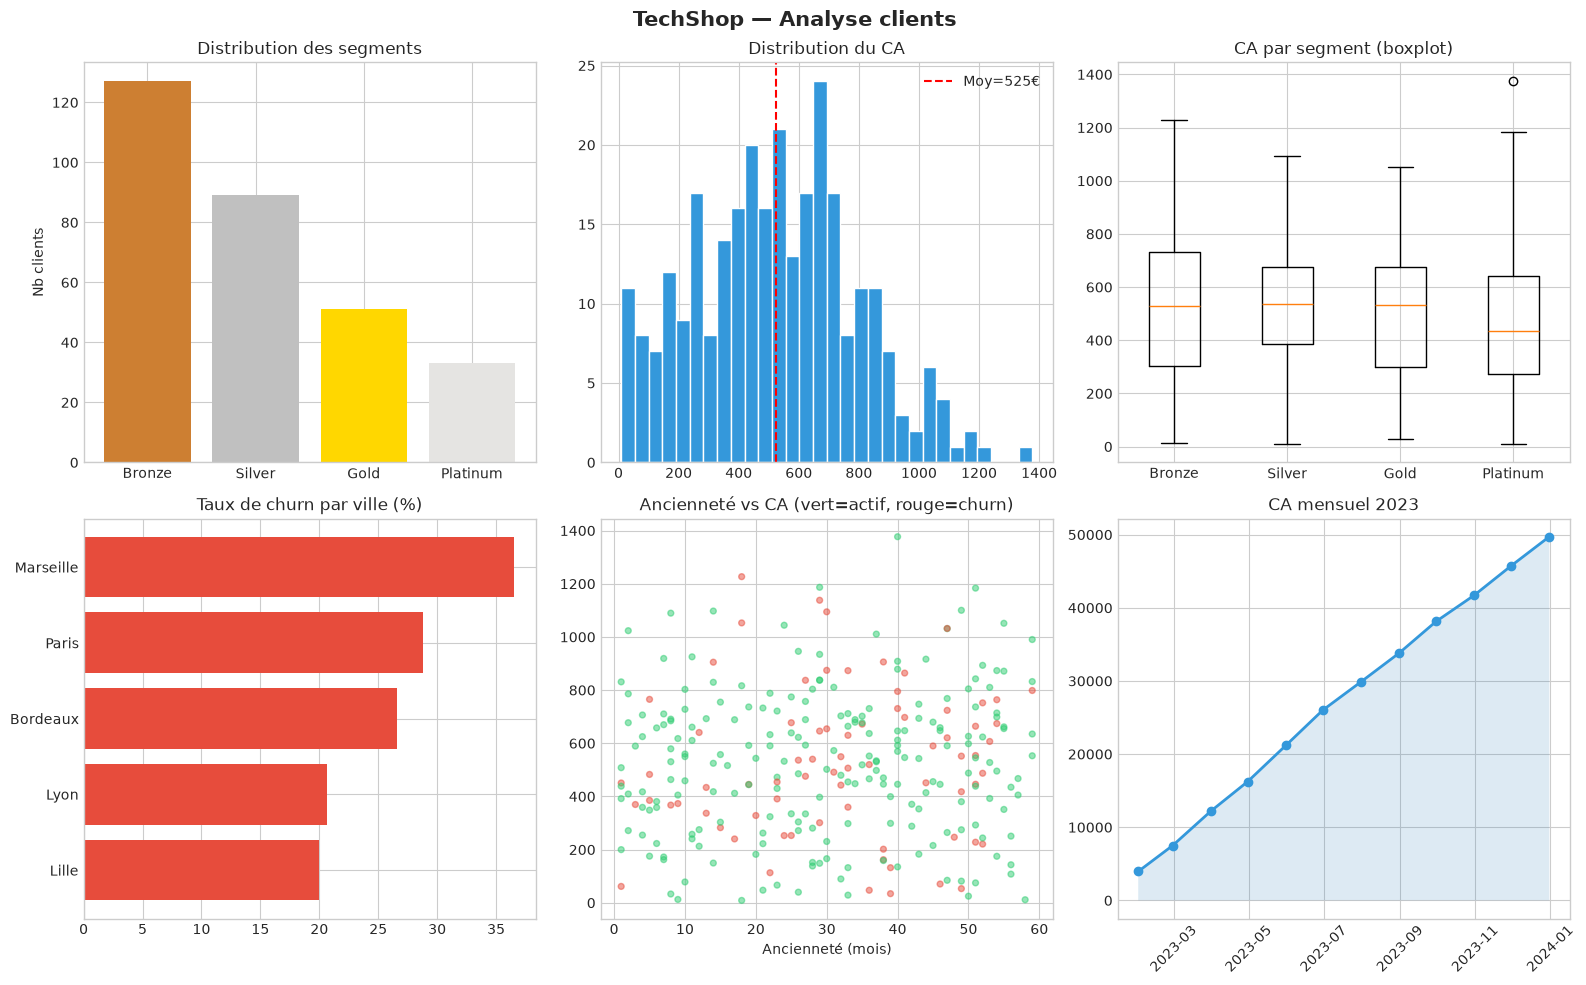

In [14]:
# 3.5 — Visualisations Matplotlib & Seaborn

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
fig.suptitle(t="TechShop — Analyse clients", fontsize=15, fontweight="bold")

# 1. Barplot segments
seg = clients_df["segment"].value_counts()
axes[0,0].bar(x=seg.index, height=seg.values, color=["#CD7F32","#C0C0C0","#FFD700","#E5E4E2"])
axes[0,0].set_title(label="Distribution des segments")
axes[0,0].set_ylabel(ylabel="Nb clients")

# 2. Histogramme CA
ca = clients_df["ca_total"].dropna()
axes[0,1].hist(x=ca, bins=30, color="#3498db", edgecolor="white")
axes[0,1].axvline(x=ca.mean(), color="red", linestyle="--", label=f"Moy={ca.mean():.0f}€")
axes[0,1].set_title(label="Distribution du CA")
axes[0,1].legend()

# 3. Boxplot CA par segment
seg_order = ["Bronze","Silver","Gold","Platinum"]
data_box = [clients_df[clients_df["segment"]==s]["ca_total"].dropna() for s in seg_order]
axes[0,2].boxplot(x=data_box, tick_labels=seg_order)
axes[0,2].set_title(label="CA par segment (boxplot)")

# 4. Barh churn par ville
churn_v = clients_df.groupby(by="ville")["churn"].mean().sort_values()
axes[1,0].barh(y=churn_v.index, width=churn_v.values*100, color="#e74c3c")
axes[1,0].set_title(label="Taux de churn par ville (%)")

# 5. Scatter ancienneté vs CA
couleurs = clients_df["churn"].map(func={0:"#2ecc71", 1:"#e74c3c"})
axes[1,1].scatter(x=clients_df["anciennete_mois"], y=clients_df["ca_total"],
                  c=couleurs, alpha=0.5, s=18)
axes[1,1].set_title(label="Ancienneté vs CA (vert=actif, rouge=churn)")
axes[1,1].set_xlabel(xlabel="Ancienneté (mois)")

# 6. Lineplot CA mensuel simulé
mois = pd.date_range(start="2023-01", periods=12, freq="ME")
ca_m = np.random.normal(loc=50000, scale=4000, size=12).cumsum()/12
axes[1,2].plot(mois, ca_m, marker="o", color="#3498db", lw=2)
axes[1,2].fill_between(x=mois, y1=ca_m, alpha=0.15)
axes[1,2].set_title(label="CA mensuel 2023")
axes[1,2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

---
<a id="4-manquants"></a>
## 4. Gestion des valeurs manquantes et des colonnes catégorielles

### Valeurs manquantes
| Méthode | Usage |
|---------|-------|
| `df.isnull().sum()` | Détecter |
| `df.fillna(val)` | Remplacer par une constante |
| `df["col"].fillna(df["col"].median())` | Remplacer par la médiane |
| `df.ffill()` / `df.bfill()` | Forward/backward fill (séries temporelles) |
| `df.dropna(subset=["col"])` | Supprimer les lignes avec NaN dans une colonne |
| `SimpleImputer` (sklearn) | Dans un pipeline ML |

### Encodage catégoriel
| Méthode | Quand l'utiliser |
|---------|-----------------|
| `pd.get_dummies()` | Variables nominales, peu de modalités, usage direct |
| `OrdinalEncoder` | Variables ordinales (Bronze < Silver < Gold) |
| `OneHotEncoder` (sklearn) | Variables nominales dans un pipeline sklearn |
| `LabelEncoder` | Variable cible binaire/multiclasse |


clients_df.isnull().mean() fonctionne en deux étapes :  
clients_df.isnull() : renvoie un DataFrame de la même taille, avec True (ou 1) partout où une valeur est manquante (NaN/None), et False (0) sinon.

.mean() : calcule la moyenne par colonne. Comme les booléens sont traités comme des 0 et des 1, la moyenne correspond simplement à la proportion de True, donc la proportion de valeurs manquantes.



=== Valeurs manquantes ===
          nb   pct
age       12  4.00
ca_total  13  4.33


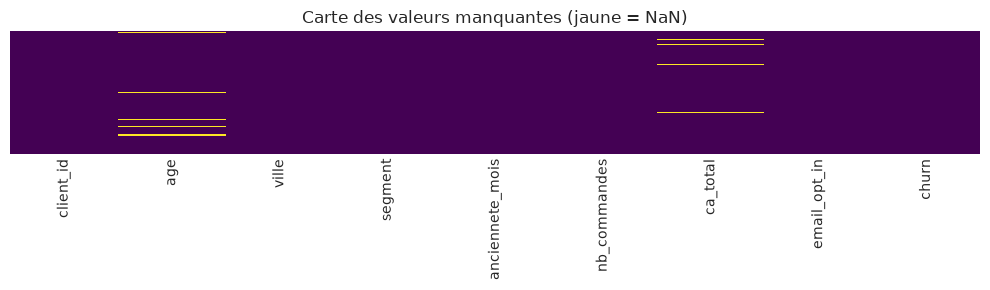

In [15]:
# 4.1 — Détection des valeurs manquantes

print("=== Valeurs manquantes ===")
vm = pd.DataFrame(data={
    "nb":  clients_df.isnull().sum(),
    "pct": (clients_df.isnull().mean()*100).round(decimals=2)
})
print(vm[vm["nb"] > 0])

# Heatmap des manquants
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(data=clients_df.isnull(), cbar=False, cmap="viridis",
            xticklabels=True, yticklabels=False, ax=ax)
ax.set_title(label="Carte des valeurs manquantes (jaune = NaN)")
plt.tight_layout()
plt.show()

In [16]:
# 4.2 — Stratégies de remplacement

df = clients_df.copy()

# Médiane pour les numériques asymétriques
mediane_age = df["age"].median()
df["age"] = df["age"].fillna(value=mediane_age)
print(f"Age manquant → médiane : {mediane_age:.0f}")

# Moyenne pour les distributions normales
moy_ca = df["ca_total"].mean()
df["ca_total"] = df["ca_total"].fillna(value=moy_ca)
print(f"CA manquant → moyenne : {moy_ca:.2f}€")

# Mode pour les catégorielles
mode_ville = df["ville"].mode()[0]
print(f"Mode ville : {mode_ville}")
# df["ville"] = df["ville"].fillna(mode_ville)

# Forward fill / backward fill (séries temporelles)
s = pd.Series(data=[10.0, None, None, 13.0, None, 15.0])
print(f"\nOriginal   : {s.tolist()}")
print(f"ffill      : {s.ffill().tolist()}")
print(f"bfill      : {s.bfill().tolist()}")
print(f"interpolé  : {s.interpolate().tolist()}")

print(f"\nManquants restants : {df.isnull().sum().sum()}")

Age manquant → médiane : 45
CA manquant → moyenne : 524.98€
Mode ville : Paris

Original   : [10.0, nan, nan, 13.0, nan, 15.0]
ffill      : [10.0, 10.0, 10.0, 13.0, 13.0, 15.0]
bfill      : [10.0, 13.0, 13.0, 13.0, 15.0, 15.0]
interpolé  : [10.0, 11.0, 12.0, 13.0, 14.0, 15.0]

Manquants restants : 0


In [17]:
# 4.3 — Encodage catégoriel

df_enc = df.copy()

# ① pd.get_dummies() — One-Hot simple
print("=== get_dummies() ===")
df_dum = pd.get_dummies(data=df_enc, columns=["ville"], prefix="ville", dtype=int)
cols_ville = [c for c in df_dum.columns if c.startswith("ville_")]
print("Colonnes créées :", cols_ville)
print(df_dum[cols_ville].head(n=3))

# ② OrdinalEncoder — préserve l'ordre naturel
print("\n=== OrdinalEncoder (Bronze < Silver < Gold < Platinum) ===")
oe = OrdinalEncoder(categories=[["Bronze","Silver","Gold","Platinum"]])
df_enc["segment_ord"] = oe.fit_transform(X=df_enc[["segment"]])
print(df_enc[["segment","segment_ord"]].drop_duplicates().sort_values(by="segment_ord"))

# ③ LabelEncoder — pour la variable cible
print("\n=== LabelEncoder (cible) ===")
le = LabelEncoder()
y_encoded = le.fit_transform(y=df_enc["segment"])
print("Classes :", le.classes_)
print("Exemple :", df_enc["segment"].head(n=4).tolist(), "→", y_encoded[:4])

=== get_dummies() ===
Colonnes créées : ['ville_Bordeaux', 'ville_Lille', 'ville_Lyon', 'ville_Marseille', 'ville_Paris']
   ville_Bordeaux  ville_Lille  ville_Lyon  ville_Marseille  ville_Paris
0               0            0           0                0            1
1               0            0           0                1            0
2               1            0           0                0            0

=== OrdinalEncoder (Bronze < Silver < Gold < Platinum) ===
     segment  segment_ord
0     Bronze          0.0
1     Silver          1.0
2       Gold          2.0
24  Platinum          3.0

=== LabelEncoder (cible) ===
Classes : ['Bronze' 'Gold' 'Platinum' 'Silver']
Exemple : ['Bronze', 'Silver', 'Gold', 'Gold'] → [0 3 1 1]


In [18]:
# 4.4 — Pipeline ColumnTransformer (preprocessing complet pour ML)

features_num = ["age", "anciennete_mois", "nb_commandes", "ca_total"]
features_cat = ["ville", "segment"]

preprocesseur = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
    ]), features_num),
    ("cat", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe",     OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), features_cat),
])

X = df[features_num + features_cat]
y = df["churn"]

X_t = preprocesseur.fit_transform(X=X)
noms_ohe = preprocesseur.named_transformers_["cat"]["ohe"].get_feature_names_out(input_features=features_cat)
all_features = features_num + list(noms_ohe)

print(f"Shape avant  : {X.shape}")
print(f"Shape après  : {X_t.shape}")
print(f"\nFeatures ({len(all_features)}) : {all_features}")

Shape avant  : (300, 6)
Shape après  : (300, 13)

Features (13) : ['age', 'anciennete_mois', 'nb_commandes', 'ca_total', 'ville_Bordeaux', 'ville_Lille', 'ville_Lyon', 'ville_Marseille', 'ville_Paris', 'segment_Bronze', 'segment_Gold', 'segment_Platinum', 'segment_Silver']


---
<a id="5-docker"></a>
## 5. Base de données relationnelle avec Docker + phpMyAdmin

```
docker-compose.yml
├── service: db          (MySQL 8.0, port 3306)
│   └── volume: db_data  (persistance)
└── service: phpmyadmin  (interface web, port 8080)
    └── depends_on: db
```

**Commandes essentielles**
```bash
docker-compose up -d              # démarrer en arrière-plan
docker-compose down               # arrêter (conserver les données)
docker-compose down -v            # arrêter + SUPPRIMER les volumes
docker-compose logs -f db         # suivre les logs en temps réel
docker ps                         # voir les conteneurs actifs
docker exec -it techshop_db mysql -u root -p   # shell MySQL
```


In [19]:
# 5.1 — Contenu du docker-compose.yml

print("""
version: "3.8"

services:
  db:
    image: mysql:8.0
    container_name: techshop_db
    restart: always
    env_file: .env
    environment:
      MYSQL_ROOT_PASSWORD: ${DB_ROOT_PASSWORD}
      MYSQL_DATABASE:      ${DB_NAME}
      MYSQL_USER:          ${DB_USER}
      MYSQL_PASSWORD:      ${DB_PASSWORD}
    ports:
      - "3306:3306"
    volumes:
      - db_data:/var/lib/mysql
      - ./sql/init.sql:/docker-entrypoint-initdb.d/init.sql
    healthcheck:
      test: ["CMD", "mysqladmin", "ping", "-h", "localhost"]
      interval: 10s
      timeout: 5s
      retries: 5

  phpmyadmin:
    image: phpmyadmin/phpmyadmin
    container_name: techshop_phpmyadmin
    environment:
      PMA_HOST: db
      PMA_PORT: 3306
    ports:
      - "8080:80"
    depends_on:
      db:
        condition: service_healthy

volumes:
  db_data:
""")


version: "3.8"

services:
  db:
    image: mysql:8.0
    container_name: techshop_db
    restart: always
    env_file: .env
    environment:
      MYSQL_ROOT_PASSWORD: ${DB_ROOT_PASSWORD}
      MYSQL_DATABASE:      ${DB_NAME}
      MYSQL_USER:          ${DB_USER}
      MYSQL_PASSWORD:      ${DB_PASSWORD}
    ports:
      - "3306:3306"
    volumes:
      - db_data:/var/lib/mysql
      - ./sql/init.sql:/docker-entrypoint-initdb.d/init.sql
    healthcheck:
      test: ["CMD", "mysqladmin", "ping", "-h", "localhost"]
      interval: 10s
      timeout: 5s
      retries: 5

  phpmyadmin:
    image: phpmyadmin/phpmyadmin
    container_name: techshop_phpmyadmin
    environment:
      PMA_HOST: db
      PMA_PORT: 3306
    ports:
      - "8080:80"
    depends_on:
      db:
        condition: service_healthy

volumes:
  db_data:



---
<a id="6-env"></a>
## 6. Variables d'environnement

**Pourquoi ?** Ne jamais mettre de credentials en dur dans le code.

**Fichier `.env`** (ne jamais committer — ajouter dans `.gitignore`) :
```ini
DB_HOST=localhost
DB_PORT=3306
DB_NAME=techshop
DB_USER=app_user
DB_PASSWORD=supersecret123
DB_ROOT_PASSWORD=rootpwd
ML_MODEL_PATH=./models/churn_v1.joblib
```

**En Python** : `os.environ.get("CLE", "valeur_par_defaut")`
**Avec dotenv** : `from dotenv import load_dotenv; load_dotenv(".env")`


In [20]:
# 6.1 — os.environ

import os

# Lecture avec valeur par défaut (ne plante pas si absente)
db_host = os.environ.get(key="DB_HOST", default="localhost")
db_port = int(os.environ.get(key="DB_PORT", default="3306"))
db_name = os.environ.get(key="DB_NAME", default="techshop")
print(f"DB_HOST={db_host}  DB_PORT={db_port}  DB_NAME={db_name}")

# Définir pour la session
os.environ["APP_ENV"] = "development"

# Variable obligatoire (levée d'exception si absente)
def require_env(key: str) -> str:
    val = os.environ.get(key=key)
    if not val:
        raise EnvironmentError(f"Variable obligatoire manquante : {key}")
    return val

try:
    api_key = require_env(key="API_KEY")
except EnvironmentError as e:
    print(f"⚠  {e}")

# Construction de l'URL SQLAlchemy depuis les variables d'env
def build_db_url() -> str:
    h = os.environ.get(key="DB_HOST",     default="localhost")
    p = os.environ.get(key="DB_PORT",     default="3306")
    n = os.environ.get(key="DB_NAME",     default="techshop")
    u = os.environ.get(key="DB_USER",     default="root")
    pw= os.environ.get(key="DB_PASSWORD", default="")
    return f"mysql+pymysql://{u}:{pw}@{h}:{p}/{n}"

print("URL DB :", build_db_url())

DB_HOST=localhost  DB_PORT=3306  DB_NAME=techshop
⚠  Variable obligatoire manquante : API_KEY
URL DB : mysql+pymysql://root:@localhost:3306/techshop


In [21]:
# 6.2 — python-dotenv

# Créer un .env de test en mémoire
env_content = """
DB_HOST=localhost
DB_PORT=3306
DB_NAME=techshop
DB_USER=app_user
DB_PASSWORD=motdepasse
ML_MODEL_PATH=./models/churn_v2.joblib
DEBUG=false
"""

env_path = "/tmp/.env_demo"
with open(file=env_path, mode="w") as f:
    f.write(env_content.strip())

# Charger avec python-dotenv
try:
    from dotenv import load_dotenv
    load_dotenv(dotenv_path=env_path, override=True)
    print("dotenv chargé")
except ImportError:
    # Simulation manuelle si dotenv non installé
    for line in env_content.strip().splitlines():
        if "=" in line and not line.startswith("#"):
            k, v = line.split(sep="=", maxsplit=1)
            os.environ[k.strip()] = v.strip()
    print("(dotenv simulé manuellement)")

print(f"DB_USER       = {os.environ.get(key='DB_USER')}")
print(f"ML_MODEL_PATH = {os.environ.get(key='ML_MODEL_PATH')}")
print(f"DEBUG         = {os.environ.get(key='DEBUG')}")

dotenv chargé
DB_USER       = app_user
ML_MODEL_PATH = ./models/churn_v2.joblib
DEBUG         = false


---
<a id="7-archi"></a>
## 7. Architecture de base de données relationnelle

### Schéma logique TechShop
```
categories ──< produits >── commande_items >── commandes ──< clients
   PK: categorie_id          PK: item_id            PK: commande_id     PK: client_id
                             FK: produit_id          FK: client_id
                             FK: commande_id
```

### Règles essentielles
- **Clé primaire (PK)** : `INT PRIMARY KEY AUTO_INCREMENT`
- **Clé étrangère (FK)** : `FOREIGN KEY (col) REFERENCES table(pk)`
- **ON DELETE CASCADE** : supprime les lignes filles
- **ON DELETE RESTRICT** : bloque si des références existent
- **ON DELETE SET NULL** : met la FK à NULL
- **INDEX** : accélère les recherches (email, segment…)


In [22]:
# 7.1 — DDL SQL : CREATE TABLE

sql_ddl = """
CREATE TABLE categories (
    categorie_id INT          PRIMARY KEY AUTO_INCREMENT,
    nom          VARCHAR(100) NOT NULL UNIQUE
);

CREATE TABLE clients (
    client_id    INT          PRIMARY KEY AUTO_INCREMENT,
    nom          VARCHAR(100) NOT NULL,
    email        VARCHAR(150) NOT NULL UNIQUE,
    ville        VARCHAR(50),
    segment      ENUM('Bronze','Silver','Gold','Platinum') DEFAULT 'Bronze',
    date_creation DATE        NOT NULL,
    actif        BOOLEAN      DEFAULT TRUE,

    INDEX idx_segment (segment),
    INDEX idx_email   (email)
);

CREATE TABLE produits (
    produit_id   INT           PRIMARY KEY AUTO_INCREMENT,
    nom          VARCHAR(150)  NOT NULL,
    prix_ht      DECIMAL(10,2) NOT NULL CHECK (prix_ht > 0),
    stock        INT           DEFAULT 0,
    categorie_id INT,

    FOREIGN KEY (categorie_id) REFERENCES categories(categorie_id)
        ON DELETE SET NULL ON UPDATE CASCADE
);

CREATE TABLE commandes (
    commande_id   INT  PRIMARY KEY AUTO_INCREMENT,
    client_id     INT  NOT NULL,
    date_commande DATE NOT NULL,
    statut        ENUM('en_attente','validee','expediee','livree','annulee')
                       DEFAULT 'en_attente',

    FOREIGN KEY (client_id) REFERENCES clients(client_id)
        ON DELETE RESTRICT ON UPDATE CASCADE
);

CREATE TABLE commande_items (
    item_id       INT           PRIMARY KEY AUTO_INCREMENT,
    commande_id   INT           NOT NULL,
    produit_id    INT           NOT NULL,
    quantite      INT           NOT NULL CHECK (quantite > 0),
    prix_unitaire DECIMAL(10,2) NOT NULL,

    FOREIGN KEY (commande_id) REFERENCES commandes(commande_id) ON DELETE CASCADE,
    FOREIGN KEY (produit_id)  REFERENCES produits(produit_id)   ON DELETE RESTRICT,
    UNIQUE KEY uq_cmd_prod (commande_id, produit_id)
);
"""
print(sql_ddl)


CREATE TABLE categories (
    categorie_id INT          PRIMARY KEY AUTO_INCREMENT,
    nom          VARCHAR(100) NOT NULL UNIQUE
);

CREATE TABLE clients (
    client_id    INT          PRIMARY KEY AUTO_INCREMENT,
    nom          VARCHAR(100) NOT NULL,
    email        VARCHAR(150) NOT NULL UNIQUE,
    ville        VARCHAR(50),
    segment      ENUM('Bronze','Silver','Gold','Platinum') DEFAULT 'Bronze',
    date_creation DATE        NOT NULL,
    actif        BOOLEAN      DEFAULT TRUE,

    INDEX idx_segment (segment),
    INDEX idx_email   (email)
);

CREATE TABLE produits (
    produit_id   INT           PRIMARY KEY AUTO_INCREMENT,
    nom          VARCHAR(150)  NOT NULL,
    prix_ht      DECIMAL(10,2) NOT NULL CHECK (prix_ht > 0),
    stock        INT           DEFAULT 0,
    categorie_id INT,

    FOREIGN KEY (categorie_id) REFERENCES categories(categorie_id)
        ON DELETE SET NULL ON UPDATE CASCADE
);

CREATE TABLE commandes (
    commande_id   INT  PRIMARY KEY AUTO_INCREME

In [42]:
# 7.2 — Requêtes SQL avec JOINs

requetes = {
    "CA par client (JOIN 3 tables)": """
SELECT c.nom, COUNT(cmd.commande_id) AS nb_cmds,
       SUM(ci.quantite * ci.prix_unitaire) AS ca_total
FROM clients c
JOIN commandes     cmd ON c.client_id     = cmd.client_id
JOIN commande_items ci ON cmd.commande_id = ci.commande_id
WHERE cmd.statut = 'livree'
GROUP BY c.client_id, c.nom
ORDER BY ca_total DESC
LIMIT 10;""",

    "Clients sans commande (LEFT JOIN + IS NULL)": """
SELECT c.client_id, c.nom, c.email
FROM clients c
LEFT JOIN commandes cmd ON c.client_id = cmd.client_id
WHERE cmd.commande_id IS NULL;""",

    "Produits en rupture de stock": """
SELECT p.nom, p.stock, cat.nom AS categorie
FROM produits p
JOIN categories cat ON p.categorie_id = cat.categorie_id
WHERE p.stock = 0
ORDER BY cat.nom, p.nom;""",
}

for titre, req in requetes.items():
    print(f"=== {titre} ===")
    print(req)

=== CA par client (JOIN 3 tables) ===

SELECT c.nom, COUNT(cmd.commande_id) AS nb_cmds,
       SUM(ci.quantite * ci.prix_unitaire) AS ca_total
FROM clients c
JOIN commandes     cmd ON c.client_id     = cmd.client_id
JOIN commande_items ci ON cmd.commande_id = ci.commande_id
WHERE cmd.statut = 'livree'
GROUP BY c.client_id, c.nom
ORDER BY ca_total DESC
LIMIT 10;
=== Clients sans commande (LEFT JOIN + IS NULL) ===

SELECT c.client_id, c.nom, c.email
FROM clients c
LEFT JOIN commandes cmd ON c.client_id = cmd.client_id
WHERE cmd.commande_id IS NULL;
=== Produits en rupture de stock ===

SELECT p.nom, p.stock, cat.nom AS categorie
FROM produits p
JOIN categories cat ON p.categorie_id = cat.categorie_id
WHERE p.stock = 0
ORDER BY cat.nom, p.nom;


---
<a id="8-sqlalchemy"></a>
## 8. SQLAlchemy & ORM

| Approche | Description |
|----------|-------------|
| **Core** | Proche SQL, utilise `text()` ou Table objects |
| **ORM** | Classes Python mappées sur les tables, Session |

### Cycle de vie ORM
```
Base = declarative_base()      # registre
class Modele(Base): ...        # définition table
Base.metadata.create_all(engine)  # création physique

with Session(engine) as session:
    session.add(obj)           # INSERT (pas encore en base)
    session.flush()            # envoi SQL, pas de commit
    session.commit()           # persistance
    session.rollback()         # annulation
```


In [23]:
# 8.1 — Engine (SQLite en mémoire pour la démo)

from sqlalchemy import (create_engine, Column, Integer, String, Float,
                        Boolean, ForeignKey, UniqueConstraint, func, desc)
from sqlalchemy.orm import declarative_base, relationship, Session
from sqlalchemy.pool import StaticPool

engine = create_engine(
    url="sqlite:///:memory:",
    connect_args={"check_same_thread": False},
    poolclass=StaticPool,
    echo=False   # True pour afficher le SQL généré
)
Base = declarative_base()
print("Engine SQLite en mémoire créé")

# Pour MySQL en production :
# engine = create_engine(
#     f"mysql+pymysql://{USER}:{PWD}@{HOST}:{PORT}/{DB}",
#     pool_size=5, max_overflow=10, pool_timeout=30
# )

Engine SQLite en mémoire créé


In [ ]:
# 8.2 — Définition des modèles ORM

from sqlalchemy import CheckFirst


class Client(Base):
    __tablename__ = "clients"
    client_id = Column(Integer, primary_key=True, autoincrement=True)
    nom       = Column(String(length=100), nullable=False)
    email     = Column(String(length=150), nullable=False, unique=True)
    ville     = Column(String(length=50))
    segment   = Column(String(length=20), default="Bronze")
    actif     = Column(Boolean, default=True)
    # Relation 1→N : un client a plusieurs commandes
    commandes = relationship(argument="Commande", back_populates="client",
                             cascade="all, delete-orphan")
    def __repr__(self):
        return f"<Client(id={self.client_id}, nom='{self.nom}', seg='{self.segment}')>"

class Produit(Base):
    __tablename__ = "produits"
    produit_id = Column(Integer, primary_key=True, autoincrement=True)
    nom        = Column(String(length=150), nullable=False)
    prix_ht    = Column(Float, nullable=False)
    stock      = Column(Integer, default=0)
    items      = relationship(argument="CommandeItem", back_populates="produit")
    def __repr__(self):
        return f"<Produit(id={self.produit_id}, nom='{self.nom}', prix={self.prix_ht})>"

class Commande(Base):
    __tablename__ = "commandes"
    commande_id = Column(Integer, primary_key=True, autoincrement=True)
    client_id   = Column(Integer, ForeignKey(column="clients.client_id"), nullable=False)
    statut      = Column(String(length=20), default="en_attente")
    client = relationship(argument="Client", back_populates="commandes")
    items  = relationship(argument="CommandeItem", back_populates="commande",
                          cascade="all, delete-orphan")
    @property
    def total(self):
        return sum(i.quantite * i.prix_unitaire for i in self.items)

class CommandeItem(Base):
    __tablename__ = "commande_items"
    __table_args__ = (UniqueConstraint("commande_id","produit_id"),)
    item_id       = Column(Integer, primary_key=True, autoincrement=True)
    commande_id   = Column(Integer, ForeignKey(column="commandes.commande_id"), nullable=False)
    produit_id    = Column(Integer, ForeignKey(column="produits.produit_id"),   nullable=False)
    quantite      = Column(Integer, nullable=False)
    prix_unitaire = Column(Float,   nullable=False)
    commande = relationship(argument="Commande", back_populates="items")
    produit  = relationship(argument="Produit",  back_populates="items")

Base.metadata.create_all(bind=engine)
print("Tables créées :", list(Base.metadata.tables.keys()))

Tables créées : ['clients', 'produits', 'commandes', 'commande_items']


In [25]:
# 8.3 — CRUD avec Session

with Session(bind=engine) as session:

    # ── CREATE ──────────────────────────────────────────────
    laptop = Produit(nom="Laptop Pro 15", prix_ht=1299.99, stock=50)
    souris = Produit(nom="Souris Ergo",   prix_ht=49.99,   stock=200)
    session.add_all(instances=[laptop, souris])
    session.flush()   # obtient les IDs sans commit

    alice = Client(nom="Alice Martin", email="alice@ex.com", ville="Paris", segment="Gold")
    bob   = Client(nom="Bob Dupont",   email="bob@ex.com",   ville="Lyon",  segment="Silver")
    session.add_all(instances=[alice, bob])
    session.flush()

    cmd1 = Commande(client_id=alice.client_id, statut="livree")
    session.add(instance=cmd1)
    session.flush()

    session.add_all(instances=[
        CommandeItem(commande_id=cmd1.commande_id, produit_id=laptop.produit_id,
                     quantite=1, prix_unitaire=1299.99),
        CommandeItem(commande_id=cmd1.commande_id, produit_id=souris.produit_id,
                     quantite=2, prix_unitaire=49.99),
    ])
    session.commit()
    print("Données insérées")

    # ── READ ────────────────────────────────────────────────
    print("\nTous les clients :", session.query(Client).all())

    # Accès via relation (chargement automatique)
    cmd = session.query(Commande).first()
    print(f"Commande #{cmd.commande_id} — client : {cmd.client.nom}")
    print(f"Items : {cmd.items}")
    print(f"Total : {cmd.total:.2f}€")

    # ── UPDATE ──────────────────────────────────────────────
    alice_db = session.query(Client).filter_by(email="alice@ex.com").first()
    alice_db.segment = "Platinum"
    session.commit()
    print(f"\nSegment Alice → {alice_db.segment}")

    # ── DELETE ──────────────────────────────────────────────
    bob_db = session.query(Client).filter_by(email="bob@ex.com").first()
    session.delete(instance=bob_db)
    session.commit()
    print(f"Bob supprimé — clients restants : {session.query(Client).count()}")

Données insérées

Tous les clients : [<Client(id=1, nom='Alice Martin', seg='Gold')>, <Client(id=2, nom='Bob Dupont', seg='Silver')>]
Commande #1 — client : Alice Martin
Items : [<__main__.CommandeItem object at 0x7f72c0564ef0>, <__main__.CommandeItem object at 0x7f72c05659d0>]
Total : 1399.97€

Segment Alice → Platinum
Bob supprimé — clients restants : 1


In [26]:
# 8.4 — Requêtes avancées ORM

from sqlalchemy import text

with Session(bind=engine) as session:

    # Agrégation
    stats = (session.query(Client.segment, func.count(Client.client_id).label(name="n"))
                    .group_by(Client.segment).all())
    print("Clients par segment :")
    for row in stats: print(f"  {row.segment}: {row.n}")

    # Jointure avec filtre
    res = (session.query(Client.nom, Commande.statut)
                  .join(target=Commande, onclause=Client.client_id == Commande.client_id)
                  .filter(Commande.statut == "livree").all())
    print("\nCommandes livrées :")
    for r in res: print(f"  {r.nom} — {r.statut}")

    # SQL brut via text()
    result = session.execute(
        statement=text(text="SELECT COUNT(*) AS n FROM commande_items WHERE quantite > :min"),
        params={"min": 0}
    ).fetchone()
    print(f"\nTotal items en base : {result.n}")

Clients par segment :
  Platinum: 1

Commandes livrées :
  Alice Martin — livree

Total items en base : 2


---
<a id="9-ml"></a>
## 9. Entraînement d'un modèle ML avec scikit-learn

**Tâche** : prédire le churn client (classification binaire)

```
Données brutes
    └─► Prétraitement (ColumnTransformer)
            └─► Pipeline (preprocesseur + modèle)
                    └─► train_test_split
                            └─► fit() sur X_train
                                    └─► predict() sur X_test
```


In [27]:
# 9.1 — Dataset ML (corrélation churn réaliste)

np.random.seed(seed=42)
N = 600

df_ml = pd.DataFrame(data={
    "age":             np.random.randint(low=18, high=75, size=N).astype(dtype=float),
    "anciennete_mois": np.random.randint(low=1, high=60, size=N),
    "nb_commandes":    np.random.poisson(lam=5, size=N),
    "ca_total":        np.abs(np.random.normal(loc=500, scale=300, size=N)),
    "ville":           np.random.choice(a=["Paris","Lyon","Marseille","Bordeaux","Lille"], size=N),
    "segment":         np.random.choice(a=["Bronze","Silver","Gold","Platinum"], size=N),
})

def gen_churn(row):
    p = 0.50
    if row["nb_commandes"] > 5:               p -= 0.20
    if row["segment"] in ["Gold","Platinum"]: p -= 0.15
    if row["ca_total"] > 700:                 p -= 0.10
    if row["anciennete_mois"] < 6:            p += 0.20
    return int(np.random.random() < max(0.05, min(0.95, p)))

df_ml["churn"] = df_ml.apply(func=gen_churn, axis=1)
df_ml.loc[np.random.choice(a=N, size=30), "age"] = np.nan  # valeurs manquantes

print(f"Dataset : {df_ml.shape}")
print(f"Taux churn : {df_ml['churn'].mean()*100:.1f}%")

Dataset : (600, 7)
Taux churn : 33.3%


In [28]:
# 9.2 — train_test_split avec stratify

feat_num = ["age","anciennete_mois","nb_commandes","ca_total"]
feat_cat = ["ville","segment"]
target   = "churn"

X = df_ml[feat_num + feat_cat]
y = df_ml[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,  # 20% test
    random_state=42,
    stratify=y       # conserve la proportion de churn dans les deux sets
)

print(f"Train : {X_train.shape[0]} | Test : {X_test.shape[0]}")
print(f"Churn train : {y_train.mean()*100:.1f}% | test : {y_test.mean()*100:.1f}%")
print("  stratify=y garantit la même distribution target dans train et test")

Train : 480 | Test : 120
Churn train : 33.3% | test : 33.3%
  stratify=y garantit la même distribution target dans train et test


In [29]:
# 9.3 — Pipelines pour plusieurs modèles

prep = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imp", SimpleImputer(strategy="median")),
        ("sc",  StandardScaler()),
    ]), feat_num),
    ("cat", Pipeline(steps=[
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), feat_cat),
])

modeles = {
    "Régression Logistique": Pipeline(steps=[("prep", prep), ("clf", LogisticRegression(max_iter=500, random_state=42))]),
    "Random Forest":         Pipeline(steps=[("prep", prep), ("clf", RandomForestClassifier(n_estimators=100, random_state=42))]),
    "Gradient Boosting":     Pipeline(steps=[("prep", prep), ("clf", GradientBoostingClassifier(n_estimators=100, random_state=42))]),
}

print(f"{'Modèle':<30} AUC-ROC CV (5-fold)")
print("-" * 50)
resultats = {}
for nom, pipe in modeles.items():
    scores = cross_val_score(estimator=pipe, X=X_train, y=y_train, cv=5, scoring="roc_auc")
    resultats[nom] = {"pipe": pipe, "auc": scores.mean(), "std": scores.std()}
    print(f"{nom:<30} {scores.mean():.4f} ± {scores.std():.4f}")

Modèle                         AUC-ROC CV (5-fold)
--------------------------------------------------
Régression Logistique          0.5666 ± 0.1049
Random Forest                  0.5485 ± 0.0811
Gradient Boosting              0.5563 ± 0.0717


In [30]:
# 9.4 — GridSearchCV pour optimiser le Random Forest

param_grid = {
    "clf__n_estimators":    [50, 100, 200],
    "clf__max_depth":       [None, 5, 10],
    "clf__min_samples_split": [2, 5],
}

gs = GridSearchCV(
    estimator=modeles["Random Forest"],
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=0
)
gs.fit(X=X_train, y=y_train)

print(f"Meilleurs paramètres : {gs.best_params_}")
print(f"Meilleur AUC CV      : {gs.best_score_:.4f}")
best_model = gs.best_estimator_

Meilleurs paramètres : {'clf__max_depth': 5, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
Meilleur AUC CV      : 0.5871


---
<a id="10-eval"></a>
## 10. Évaluation & sauvegarde d'un modèle ML

| Métrique | Formule | Quand l'utiliser |
|----------|---------|-----------------|
| Accuracy | (TP+TN)/Total | Classes équilibrées |
| Precision | TP/(TP+FP) | Coût des faux positifs |
| Recall | TP/(TP+FN) | Coût des faux négatifs |
| F1-Score | 2·P·R/(P+R) | Équilibre |
| AUC-ROC | Aire sous ROC | Comparaison de modèles |


L'AUC-ROC ne s'applique qu'à la classification (pour la régression : R², RMSE, MAE)

In [31]:
# 10.1 — Métriques sur le jeu de test

y_pred  = best_model.predict(X=X_test)
y_proba = best_model.predict_proba(X=X_test)[:, 1]

print("=== Rapport de classification ===")
print(classification_report(y_true=y_test, y_pred=y_pred, target_names=["Actif","Churn"]))

auc = roc_auc_score(y_true=y_test, y_score=y_proba)
print(f"AUC-ROC : {auc:.4f}")

cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nMatrice de confusion :")
print(f"  TN={tn}  FP={fp}")
print(f"  FN={fn}  TP={tp}")

=== Rapport de classification ===
              precision    recall  f1-score   support

       Actif       0.70      0.96      0.81        80
       Churn       0.70      0.17      0.28        40

    accuracy                           0.70       120
   macro avg       0.70      0.57      0.55       120
weighted avg       0.70      0.70      0.63       120

AUC-ROC : 0.6162

Matrice de confusion :
  TN=77  FP=3
  FN=33  TP=7


15:27:40 | DEBUG    | matplotlib.font_manager | findfont: Matching sans\-serif:style=normal:variant=normal:weight=bold:stretch=normal:size=14.0.
15:27:40 | DEBUG    | matplotlib.font_manager | findfont: score(FontEntry(fname='/mnt/c/Users/Alexandre/Desktop/fiches_revision/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSerif.ttf', index=0, name='DejaVu Serif', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.335
15:27:40 | DEBUG    | matplotlib.font_manager | findfont: score(FontEntry(fname='/mnt/c/Users/Alexandre/Desktop/fiches_revision/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizTwoSymBol.ttf', index=0, name='STIXSizeTwoSym', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.05
15:27:40 | DEBUG    | matplotlib.font_manager | findfont: score(FontEntry(fname='/mnt/c/Users/Alexandre/Desktop/fiches_revision/.venv/lib/python3.12/site-packages/matplotlib/mpl-data/fo

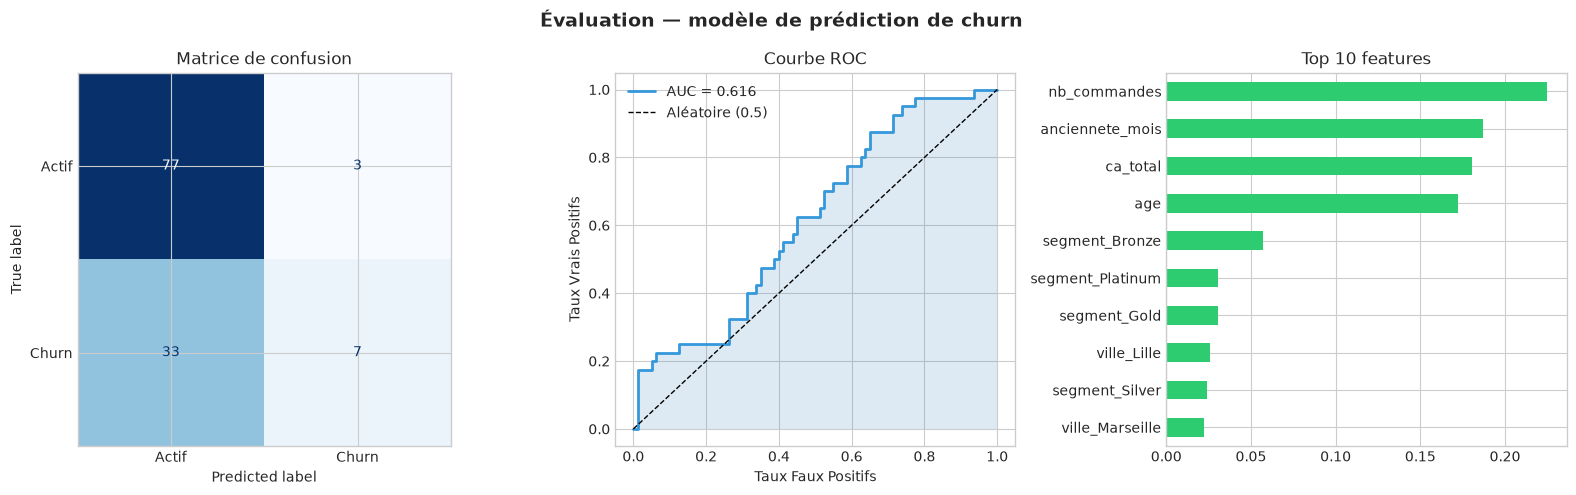

In [32]:
# 10.2 — Visualisations : matrice, ROC, importances

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))
fig.suptitle(t="Évaluation — modèle de prédiction de churn", fontsize=14, fontweight="bold")

# Matrice de confusion
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Actif","Churn"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(label="Matrice de confusion")

# Courbe ROC
fpr, tpr, _ = roc_curve(y_true=y_test, y_score=y_proba)
axes[1].plot(fpr, tpr, color="#3498db", lw=2, label=f"AUC = {auc:.3f}")
axes[1].plot([0,1],[0,1],"k--", lw=1, label="Aléatoire (0.5)")
axes[1].fill_between(x=fpr, y1=tpr, alpha=0.15)
axes[1].set_xlabel(xlabel="Taux Faux Positifs"); axes[1].set_ylabel(ylabel="Taux Vrais Positifs")
axes[1].set_title(label="Courbe ROC"); axes[1].legend()

# Importances des features
rf_clf = best_model.named_steps["clf"]
ohe_feats = best_model.named_steps["prep"].named_transformers_["cat"]["ohe"].get_feature_names_out(input_features=feat_cat)
all_feat  = feat_num + list(ohe_feats)
imp = pd.Series(data=rf_clf.feature_importances_, index=all_feat).sort_values().tail(n=10)
imp.plot(kind="barh", ax=axes[2], color="#2ecc71")
axes[2].set_title(label="Top 10 features")

plt.tight_layout()
plt.show()

In [33]:
# 10.3 — Sauvegarde et rechargement avec joblib

model_path = Path("/tmp/churn_model_v1.joblib")

# Sauvegarde
joblib.dump(value=best_model, filename=model_path)
print(f"Modèle sauvegardé : {model_path} ({model_path.stat().st_size/1024:.1f} Ko)")

# Rechargement
model_reload = joblib.load(filename=model_path)
print(f"Modèle rechargé  : {type(model_reload)}")

# Vérification : mêmes prédictions
assert (best_model.predict(X=X_test) == model_reload.predict(X=X_test)).all()
print("Prédictions identiques avant/après rechargement")

# Sauvegarde avec métadonnées
bundle = {
    "model":    best_model,
    "features": feat_num + feat_cat,
    "target":   "churn",
    "auc_test": auc,
    "date":     datetime.date.today().isoformat(),
    "version":  "1.0",
}
joblib.dump(value=bundle, filename="/tmp/churn_bundle.joblib")
b = joblib.load(filename="/tmp/churn_bundle.joblib")
print(f"\nBundle chargé — AUC test : {b['auc_test']:.4f}, version : {b['version']}")

Modèle sauvegardé : /tmp/churn_model_v1.joblib (397.0 Ko)
Modèle rechargé  : <class 'sklearn.pipeline.Pipeline'>
Prédictions identiques avant/après rechargement

Bundle chargé — AUC test : 0.6162, version : 1.0


In [34]:
# 10.4 — Prédiction sur de nouvelles données

nouveaux = pd.DataFrame(data={
    "age":             [28, 55, None, 42],
    "anciennete_mois": [3,  48,  24,  12],
    "nb_commandes":    [1,  15,   8,   2],
    "ca_total":        [120, 2500, 800, 200],
    "ville":           ["Paris","Lyon","Marseille","Bordeaux"],
    "segment":         ["Bronze","Platinum","Gold","Silver"],
})

# Le pipeline gère les NaN automatiquement grâce au SimpleImputer
probas = model_reload.predict_proba(X=nouveaux)[:, 1]
preds  = model_reload.predict(X=nouveaux)

nouveaux["proba_churn"] = probas.round(decimals=3)
nouveaux["prediction"]  = preds
nouveaux["risque"] = pd.cut(x=probas, bins=[0,.3,.6,1.],
                            labels=["Faible","Moyen","Élevé"])

print(nouveaux[["age","segment","nb_commandes","proba_churn","risque"]].to_string(index=False))

 age  segment  nb_commandes  proba_churn risque
28.0   Bronze             1        0.489  Moyen
55.0 Platinum            15        0.338  Moyen
 NaN     Gold             8        0.161 Faible
42.0   Silver             2        0.333  Moyen


---
<a id="11-compose"></a>
## 11. Docker Compose en production — Collecte & ingestion

```
services:
  db         → MySQL (service_healthy via healthcheck)
  phpmyadmin → interface admin
  collector  → script one-shot de collecte (restart: "no")
  ingester   → ETL Python vers la BDD
```

**Bonnes pratiques**
- `healthcheck` + `condition: service_healthy` sur `depends_on` → évite les race conditions
- `env_file: .env` → pas de secrets en clair dans le YAML
- Volumes nommés pour la BDD (indépendant du chemin hôte)
- Réseau `backend` interne → les services ne sont pas exposés inutilement


In [35]:
# 11.1 — docker-compose.yml complet

print("""
version: "3.8"

services:

  db:
    image: mysql:8.0
    container_name: techshop_db
    restart: always
    env_file: .env
    environment:
      MYSQL_ROOT_PASSWORD: ${DB_ROOT_PASSWORD}
      MYSQL_DATABASE:      ${DB_NAME}
      MYSQL_USER:          ${DB_USER}
      MYSQL_PASSWORD:      ${DB_PASSWORD}
    volumes:
      - db_data:/var/lib/mysql
      - ./sql/init.sql:/docker-entrypoint-initdb.d/init.sql
    networks: [backend]
    healthcheck:
      test: ["CMD","mysqladmin","ping","-h","localhost"]
      interval: 10s
      timeout: 5s
      retries: 5

  phpmyadmin:
    image: phpmyadmin/phpmyadmin
    ports: ["8080:80"]
    environment: {PMA_HOST: db}
    depends_on:
      db: {condition: service_healthy}
    networks: [backend]

  collector:
    build: ./services/collector
    container_name: techshop_collector
    restart: "no"
    env_file: .env
    volumes: ["./data:/app/data", "./logs:/app/logs"]
    networks: [backend]
    depends_on:
      db: {condition: service_healthy}

  ingester:
    build: ./services/ingester
    container_name: techshop_ingester
    restart: "no"
    env_file: .env
    volumes: ["./data:/app/data","./logs:/app/logs","./models:/app/models"]
    networks: [backend]
    depends_on:
      db: {condition: service_healthy}

networks:
  backend: {driver: bridge}

volumes:
  db_data:
""")


version: "3.8"

services:

  db:
    image: mysql:8.0
    container_name: techshop_db
    restart: always
    env_file: .env
    environment:
      MYSQL_ROOT_PASSWORD: ${DB_ROOT_PASSWORD}
      MYSQL_DATABASE:      ${DB_NAME}
      MYSQL_USER:          ${DB_USER}
      MYSQL_PASSWORD:      ${DB_PASSWORD}
    volumes:
      - db_data:/var/lib/mysql
      - ./sql/init.sql:/docker-entrypoint-initdb.d/init.sql
    networks: [backend]
    healthcheck:
      test: ["CMD","mysqladmin","ping","-h","localhost"]
      interval: 10s
      timeout: 5s
      retries: 5

  phpmyadmin:
    image: phpmyadmin/phpmyadmin
    ports: ["8080:80"]
    environment: {PMA_HOST: db}
    depends_on:
      db: {condition: service_healthy}
    networks: [backend]

  collector:
    build: ./services/collector
    container_name: techshop_collector
    restart: "no"
    env_file: .env
    volumes: ["./data:/app/data", "./logs:/app/logs"]
    networks: [backend]
    depends_on:
      db: {condition: service_healthy

In [36]:
# 11.2 — Dockerfile minimal pour un service Python

print("""
# services/ingester/Dockerfile
FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY . .

CMD ["python", "ingest.py"]
""")

print("""
# requirements.txt
pandas==2.2.0
sqlalchemy==2.0.27
pymysql==1.1.0
python-dotenv==1.0.1
joblib==1.3.2
scikit-learn==1.4.0
""")


# services/ingester/Dockerfile
FROM python:3.11-slim

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY . .

CMD ["python", "ingest.py"]


# requirements.txt
pandas==2.2.0
sqlalchemy==2.0.27
pymysql==1.1.0
python-dotenv==1.0.1
joblib==1.3.2
scikit-learn==1.4.0



---
<a id="12-tests"></a>
## 12. Tests robustes pour l'ingestion de données

### Que tester ?
1. **Validation de schéma** : colonnes requises, types, contraintes
2. **Détection de doublons** : même identifiant plusieurs fois
3. **Gestion des erreurs** : fichier manquant, format invalide, contrainte BDD
4. **Comportement aux limites** : liste vide, valeurs à la frontière

### Anatomie d'un test unittest
```python
class TestMaFonction(unittest.TestCase):
    def setUp(self):    # exécuté avant chaque test
        ...
    def test_cas_nominal(self):
        self.assertEqual(ma_func(x), valeur_attendue)
    def test_cas_erreur(self):
        with self.assertRaises(ValueError):
            ma_func(valeur_invalide)
```


In [37]:
# 12.1 — Fonctions d'ingestion à tester

SCHEMA = {
    "commande_id": int,
    "client_id":   int,
    "date":        str,
    "montant":     float,
    "statut":      str,
}
STATUTS = {"en_attente","validee","expediee","livree","annulee"}


def valider_commande(cmd: dict) -> tuple:
    """Retourne (valide: bool, erreurs: list)."""
    errs = []
    for champ, typ in SCHEMA.items():
        if champ not in cmd:
            errs.append(f"Champ manquant : '{champ}'")
        elif not isinstance(cmd[champ], typ):
            errs.append(f"Type invalide pour '{champ}' : attendu {typ.__name__}, "
                        f"reçu {type(cmd[champ]).__name__}")
    if cmd.get("statut") not in STATUTS:
        errs.append(f"Statut inconnu : '{cmd.get('statut')}'")
    if isinstance(cmd.get("montant"), float) and cmd["montant"] <= 0:
        errs.append("Montant doit être > 0")
    return (len(errs) == 0, errs)


def detecter_doublons(commandes: list) -> dict:
    vus, dbl = set(), []
    for c in commandes:
        cid = c.get("commande_id")
        if cid in vus: dbl.append(cid)
        vus.add(cid)
    return {"total": len(commandes), "uniques": len(vus),
            "doublons": dbl, "nb_doublons": len(dbl)}


def ingerer_safe(commandes: list) -> dict:
    res = {"succes": 0, "echecs": [], "doublons": 0}
    traites = set()
    for cmd in commandes:
        if cmd.get("commande_id") in traites:
            res["doublons"] += 1; continue
        ok, errs = valider_commande(cmd=cmd)
        if not ok:
            res["echecs"].append({"id": cmd.get("commande_id"), "erreurs": errs}); continue
        traites.add(cmd["commande_id"])
        res["succes"] += 1
    return res

print("Fonctions d'ingestion définies.")

Fonctions d'ingestion définies.


In [38]:
# 12.2 — Tests unitaires avec unittest

CMD_OK = {"commande_id": 101, "client_id": 1,
          "date": "2024-03-15", "montant": 150.50, "statut": "validee"}

class TestValidation(unittest.TestCase):

    def test_commande_valide(self):
        ok, errs = valider_commande(cmd=CMD_OK)
        self.assertTrue(expr=ok)
        self.assertEqual(first=errs, second=[])

    def test_champ_manquant(self):
        cmd = {k:v for k,v in CMD_OK.items() if k != "montant"}
        ok, errs = valider_commande(cmd=cmd)
        self.assertFalse(expr=ok)
        self.assertTrue(expr=any("montant" in e for e in errs))

    def test_type_incorrect(self):
        cmd = {**CMD_OK, "montant": "150.50"}   # str au lieu de float
        ok, _ = valider_commande(cmd=cmd)
        self.assertFalse(expr=ok)

    def test_statut_invalide(self):
        cmd = {**CMD_OK, "statut": "inconnu"}
        ok, errs = valider_commande(cmd=cmd)
        self.assertFalse(expr=ok)
        self.assertTrue(expr=any("Statut" in e for e in errs))

    def test_montant_negatif(self):
        cmd = {**CMD_OK, "montant": -50.0}
        ok, _ = valider_commande(cmd=cmd)
        self.assertFalse(expr=ok)


class TestDoublons(unittest.TestCase):

    def test_sans_doublons(self):
        r = detecter_doublons(commandes=[{"commande_id": 1}, {"commande_id": 2}])
        self.assertEqual(first=r["nb_doublons"], second=0)

    def test_avec_doublon(self):
        r = detecter_doublons(commandes=[{"commande_id": 1}, {"commande_id": 2}, {"commande_id": 1}])
        self.assertEqual(first=r["nb_doublons"], second=1)
        self.assertIn(member=1, container=r["doublons"])

    def test_liste_vide(self):
        r = detecter_doublons(commandes=[])
        self.assertEqual(first=r["total"], second=0)


class TestIngestionSafe(unittest.TestCase):

    def test_nominal(self):
        cmds = [
            {**CMD_OK},
            {"commande_id": 102, "client_id": 2, "date": "2024-03", "montant": 200.0, "statut": "livree"},
        ]
        r = ingerer_safe(commandes=cmds)
        self.assertEqual(first=r["succes"], second=2)
        self.assertEqual(first=r["doublons"], second=0)
        self.assertEqual(first=len(r["echecs"]), second=0)

    def test_doublon_et_erreur(self):
        cmds = [
            {**CMD_OK},
            {**CMD_OK},                             # doublon
            {"commande_id": 999, "statut": "nope"}, # erreurs multiples
        ]
        r = ingerer_safe(commandes=cmds)
        self.assertEqual(first=r["succes"],   second=1)
        self.assertEqual(first=r["doublons"], second=1)
        self.assertEqual(first=len(r["echecs"]), second=1)


# Lancement des tests dans le notebook
suite = unittest.TestLoader().loadTestsFromTestCase(testCaseClass=TestValidation)
suite.addTests(tests=unittest.TestLoader().loadTestsFromTestCase(testCaseClass=TestDoublons))
suite.addTests(tests=unittest.TestLoader().loadTestsFromTestCase(testCaseClass=TestIngestionSafe))

runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(test=suite)
print("\n" + ("SUCCES" if result.wasSuccessful() else "ECHEC"))

test_champ_manquant (__main__.TestValidation.test_champ_manquant) ... ok
test_commande_valide (__main__.TestValidation.test_commande_valide) ... ok
test_montant_negatif (__main__.TestValidation.test_montant_negatif) ... ok
test_statut_invalide (__main__.TestValidation.test_statut_invalide) ... ok
test_type_incorrect (__main__.TestValidation.test_type_incorrect) ... ok
test_avec_doublon (__main__.TestDoublons.test_avec_doublon) ... ok
test_liste_vide (__main__.TestDoublons.test_liste_vide) ... ok
test_sans_doublons (__main__.TestDoublons.test_sans_doublons) ... ok
test_doublon_et_erreur (__main__.TestIngestionSafe.test_doublon_et_erreur) ... ok
test_nominal (__main__.TestIngestionSafe.test_nominal) ... ok

----------------------------------------------------------------------
Ran 10 tests in 0.013s

OK



SUCCES


In [39]:
# 12.3 — Validation de schéma DataFrame

def valider_df(df: pd.DataFrame, schema: dict) -> dict:
    """
    schema : {col: {nullable, min, valeurs_valides}}
    """
    errs = []
    for col, r in schema.items():
        if col not in df.columns:
            errs.append(f"Colonne manquante : '{col}'"); continue
        if not r.get("nullable", True) and df[col].isnull().any():
            errs.append(f"'{col}' : {df[col].isnull().sum()} NaN non autorisés")
        if "min" in r:
            n = (df[col].dropna() < r["min"]).sum()
            if n: errs.append(f"'{col}' : {n} valeurs < {r['min']}")
        if "valeurs_valides" in r:
            bad = ~df[col].isin(values=r["valeurs_valides"])
            if bad.any():
                ex = df[col][bad].unique()[:3]
                errs.append(f"'{col}' : valeurs invalides ex. {ex}")
    return {"valide": not errs, "erreurs": errs}


schema_clients = {
    "client_id":    {"nullable": False, "min": 1},
    "segment":      {"nullable": False,
                     "valeurs_valides": {"Bronze","Silver","Gold","Platinum"}},
    "nb_commandes": {"min": 0},
    "ca_total":     {"min": 0},
}

# Test sur le dataset propre
r1 = valider_df(df=clients_df, schema=schema_clients)
print(f"Dataset propre    — valide : {r1['valide']}")

# Test sur un dataset corrompu
df_bad = clients_df.copy()
df_bad.loc[0, "segment"]      = "Ultra"
df_bad.loc[1, "nb_commandes"] = -5
df_bad.loc[2, "client_id"]    = None

r2 = valider_df(df=df_bad, schema=schema_clients)
print(f"Dataset corrompu  — valide : {r2['valide']}")
for e in r2["erreurs"]: print(f"  ❌ {e}")

Dataset propre    — valide : True
Dataset corrompu  — valide : False
  ❌ 'client_id' : 1 NaN non autorisés
  ❌ 'segment' : valeurs invalides ex. <StringArray>
['Ultra']
Length: 1, dtype: str
  ❌ 'nb_commandes' : 1 valeurs < 0


---
<a id="13-eco"></a>
## 13. Impact écologique d'un projet data

### Facteurs
- **Durée de calcul** (secondes)
- **TDP** (Thermal Design Power du CPU/GPU, en watts)
- **PUE** (Power Usage Effectiveness du datacenter : 1.0 = parfait, ~1.5 = typique)
- **Intensité carbone** (gCO₂/Wh selon le mix énergétique)

### Outil recommandé : [CodeCarbon](https://codecarbon.io/)
```python
from codecarbon import EmissionsTracker
tracker = EmissionsTracker()
tracker.start()
# ... code à mesurer ...
emissions = tracker.stop()   # kg CO₂
```

**Intensités carbonées (ordre de grandeur 2024)** :
- France : ~0.06 gCO₂/Wh (nucléaire)
- Allemagne : ~0.40 gCO₂/Wh
- USA (moy.) : ~0.38 gCO₂/Wh
- Norvège : ~0.03 gCO₂/Wh (hydraulique)


In [40]:
# 13.1 — Mesure avec codecarbon

try:
    from codecarbon import EmissionsTracker
    tracker = EmissionsTracker(project_name="TechShop_ML", log_level="error",
                               save_to_file=False)
    tracker.start()
    # code mesuré
    Pipeline(steps=[("prep", prep), ("clf", RandomForestClassifier(n_estimators=100,random_state=42))]
             ).fit(X=X_train, y=y_train)
    emissions_kg = tracker.stop()
    print(f"Emissions CO2 : {emissions_kg*1000:.4f} g CO2")
except ImportError:
    emissions_kg = 2.5e-5   # valeur typique simulée
    print(f"codecarbon non installe — emission simulee : {emissions_kg*1000:.4f} g CO2")
    print("  Installer avec : pip install codecarbon")

codecarbon non installe — emission simulee : 0.0250 g CO2
  Installer avec : pip install codecarbon


In [41]:
# 13.2 — Calcul manuel de la consommation

def estimer_impact(duree_s: float, tdp_w: float = 65,
                   pue: float = 1.5, ic_gco2_wh: float = 0.357) -> dict:
    """
    duree_s : durée en secondes
    tdp_w   : puissance du CPU en watts (65W = CPU desktop)
    pue     : overhead datacenter (1.5 = typique)
    ic      : intensité carbone du réseau électrique (gCO2/Wh)
    """
    energie_cpu_wh    = tdp_w * duree_s / 3600
    energie_totale_wh = energie_cpu_wh * pue
    emissions_g       = energie_totale_wh * ic_gco2_wh
    return {
        "duree_s": duree_s,
        "energie_wh": round(number=energie_totale_wh, ndigits=6),
        "co2_g":      round(number=emissions_g,       ndigits=6),
    }

scenarios = [
    ("Entraînement RF 30s (laptop)",         30,  45, 1.0, 0.06),
    ("Entraînement RF 30s (datacenter FR)",  30,  65, 1.5, 0.06),
    ("GridSearchCV 5min (datacenter FR)",   300,  65, 1.5, 0.06),
    ("Même chose — mix USA",               300,  65, 1.5, 0.38),
    ("Inférence 1000 req. 10s",             10,  45, 1.5, 0.06),
]

print(f"{'Scénario':<44} {'Énergie (Wh)':>12} {'CO2 (g)':>10}")
print("-" * 70)
for nom, d, tdp, pue, ic in scenarios:
    r = estimer_impact(duree_s=d, tdp_w=tdp, pue=pue, ic_gco2_wh=ic)
    print(f"{nom:<44} {r['energie_wh']:>12.6f} {r['co2_g']:>10.6f}")

print("""
Bonnes pratiques :
  - Choisir une région cloud à faible intensité carbone (France, Norvège)
  - Réutiliser les modèles (joblib) plutôt que de ré-entraîner
  - Utiliser l'early stopping pour limiter les epochs inutiles
  - Préférer les petits modèles si la performance est similaire
  - Mesurer avec codecarbon et inclure le résultat dans les rapports
""")

Scénario                                     Énergie (Wh)    CO2 (g)
----------------------------------------------------------------------
Entraînement RF 30s (laptop)                     0.375000   0.022500
Entraînement RF 30s (datacenter FR)              0.812500   0.048750
GridSearchCV 5min (datacenter FR)                8.125000   0.487500
Même chose — mix USA                             8.125000   3.087500
Inférence 1000 req. 10s                          0.187500   0.011250

Bonnes pratiques :
  - Choisir une région cloud à faible intensité carbone (France, Norvège)
  - Réutiliser les modèles (joblib) plutôt que de ré-entraîner
  - Utiliser l'early stopping pour limiter les epochs inutiles
  - Préférer les petits modèles si la performance est similaire
  - Mesurer avec codecarbon et inclure le résultat dans les rapports



---
## Cheat Sheet finale

| Sujet | Snippet clé |
|-------|------------|
| JSON → dict | `json.loads(s)` |
| dict → JSON | `json.dumps(d, indent=2)` |
| JSON imbriqué → DF | `pd.json_normalize(data, record_path=[...], meta=[...])` |
| Manquants | `df.isnull().sum()` → `df.fillna(mediane)` |
| Encodage ordinal | `OrdinalEncoder(categories=[['Bronze','Silver','Gold']])` |
| Pipeline sklearn | `Pipeline([('prep', prep), ('clf', modele)])` |
| Split stratifié | `train_test_split(X, y, test_size=0.2, stratify=y)` |
| Cross-validation | `cross_val_score(pipe, X, y, cv=5, scoring='roc_auc')` |
| GridSearchCV | `GridSearchCV(pipe, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)` |
| Sauvegarder | `joblib.dump(model, 'model.joblib')` |
| Charger | `joblib.load('model.joblib')` |
| ORM — ajouter | `session.add(obj); session.commit()` |
| ORM — requête | `session.query(Client).filter(Client.segment=='Gold').all()` |
| ORM — SQL brut | `session.execute(text("SELECT ..."), {"param": val})` |
| Var env | `os.environ.get('DB_HOST', 'localhost')` |
| Docker start | `docker-compose up -d` |
| Docker logs | `docker-compose logs -f db` |

---
> **Bonne chance pour l'examen !**
